# Logistic Regression - Sentiment Analysis

This code loads and cleans the sample data and is copied over from Reviews_Feature_Engineering.ipynb.

In [2]:
import pandas as pd
import re

reviews_path = '../data/group_sample_seed48.csv'
df = pd.read_csv(reviews_path)

# Clean the data
# 1) Remove the 2 rows with a missing summary
# 2) Remove duplicate review text (same review posted under multiple product variants),
#    keeping the first copy, so the same review can't end up in both train and test
clean_df = df.dropna(subset=["Summary"]).copy()
clean_df = clean_df.drop_duplicates(subset=["Text"]).copy()

# Convert star ratings into three sentiment groups
sentiment_map = {
    1: "Negative",
    2: "Negative",
    3: "Neutral",
    4: "Positive",
    5: "Positive"
}

clean_df["Sentiment"] = clean_df["Score"].map(sentiment_map)

# Create a function that cleans pieces of text. This will clean up all of the html text thats in the reviews and then get rid of the extra
# whitespace after from cleaning html tags
def clean_text(text):
    # Remove HTML tags
    text = re.sub(r"<[^>]+>", " ", text)

    # Remove extra spaces and line breaks
    text = " ".join(text.split())

    return text


# Clean summaries and reviews without changing the original columns
clean_df["CleanSummary"] = clean_df["Summary"].apply(clean_text)
clean_df["CleanText"] = clean_df["Text"].apply(clean_text)

# Combine the summary and review to get one large text
clean_df["CombinedText"] = (clean_df["CleanSummary"] + " " + clean_df["CleanText"])

clean_df.head()


,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text,Sentiment,CleanSummary,CleanText,CombinedText
0,515539,B001U8CED2,A38XS08I7CNOUY,nncym,3,4,1,1300060800,Nasty Stuff - Cats Hate It!,I am owned by 5 cats and I foster another 17 c...,Negative,Nasty Stuff - Cats Hate It!,I am owned by 5 cats and I foster another 17 c...,Nasty Stuff - Cats Hate It! I am owned by 5 ca...
1,318059,B0024NKMEU,A1W1TQI2UZDY4R,Charles Baker,1,1,5,1269475200,Jerky spice,"This pack was exceptional for a ""newbie"" jerky...",Positive,Jerky spice,"This pack was exceptional for a ""newbie"" jerky...","Jerky spice This pack was exceptional for a ""n..."
2,34626,B000GQTP1S,A1DRP529AHD8F1,"Ralph Kuser ""seeking intelligent life""",1,2,5,1302393600,Nice and hot!,These chips are just hot enough to make them i...,Positive,Nice and hot!,These chips are just hot enough to make them i...,Nice and hot! These chips are just hot enough ...
3,131230,B00004RAMX,A275XT9A7OV1PL,wayfarer,0,0,1,1318550400,Junky gopher trap,This trap is very poor quality. Lock bar was t...,Negative,Junky gopher trap,This trap is very poor quality. Lock bar was t...,Junky gopher trap This trap is very poor quali...
4,312766,B003KJ0DDC,A18QI1MZI0L8KB,"L. Arters ""living with MS""",0,0,5,1349827200,Delicious,I love these whole wheat crackers by Lance! I...,Positive,Delicious,I love these whole wheat crackers by Lance! It...,Delicious I love these whole wheat crackers by...


This code splits the data and then computes the TF-IDF matrices for testing and training. Copied over from Reviews_Feature_Engineering

In [3]:
from sklearn.model_selection import train_test_split

# Use 80% of the reviews for training and 20% for testing
train_df, test_df = train_test_split(
    clean_df,
    test_size=0.20,                 # 80/20 split
    random_state=48,                # Make it reproducible
    stratify=clean_df["Sentiment"]  # Keeps the class proportions similar
)

# Select the combined summary and review text as model inputs
train_text = train_df["CombinedText"]
test_text = test_df["CombinedText"]

# Select the sentiment labels that the models will learn to predict
train_labels = train_df["Sentiment"]
test_labels = test_df["Sentiment"]

# Import the TF-IDF tool
from sklearn.feature_extraction.text import TfidfVectorizer

# Include individual words only 
tfidf = TfidfVectorizer()

# Learn the vocabulary and weights from training reviews
train_tfidf = tfidf.fit_transform(train_text)

# Use the same vocabulary and weights for testing reviews
test_tfidf = tfidf.transform(test_text)

# Show the number of reviews and features
print("Training matrix shape:", train_tfidf.shape)
print("Testing matrix shape:", test_tfidf.shape)

Training matrix shape: (37008, 38244)
Testing matrix shape: (9253, 38244)


This code gives a reuseable evaluation function for the different models.

In [4]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

labels = ["Negative", "Neutral", "Positive"]

def evaluate(name, true_labels, predicted_labels):
    print(name)
    print(classification_report(true_labels, predicted_labels, labels=labels, zero_division=0))

    ConfusionMatrixDisplay.from_predictions(
        true_labels,
        predicted_labels,
        labels=labels
    )
    plt.title(name)
    plt.show()

Matplotlib is building the font cache; this may take a moment.


Majority Class Baseline

Majority Baseline
              precision    recall  f1-score   support

    Negative       0.00      0.00      0.00      1331
     Neutral       0.00      0.00      0.00       709
    Positive       0.78      1.00      0.88      7213

    accuracy                           0.78      9253
   macro avg       0.26      0.33      0.29      9253
weighted avg       0.61      0.78      0.68      9253



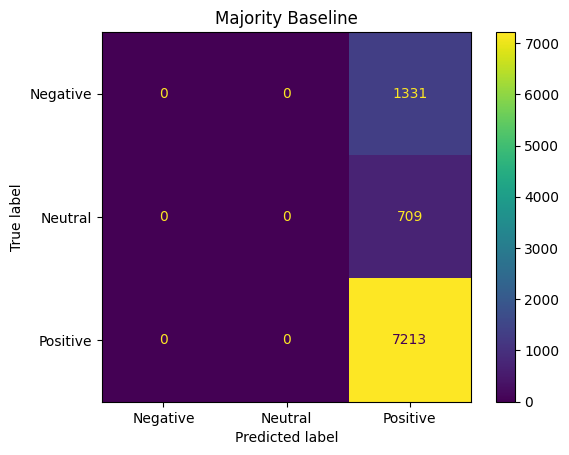

In [5]:
from sklearn.dummy import DummyClassifier

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(train_tfidf, train_labels)
evaluate("Majority Baseline", test_labels, baseline.predict(test_tfidf))

Logistic Regression

Logistic Regression
              precision    recall  f1-score   support

    Negative       0.78      0.65      0.71      1331
     Neutral       0.47      0.15      0.23       709
    Positive       0.89      0.98      0.93      7213

    accuracy                           0.87      9253
   macro avg       0.71      0.59      0.62      9253
weighted avg       0.84      0.87      0.85      9253



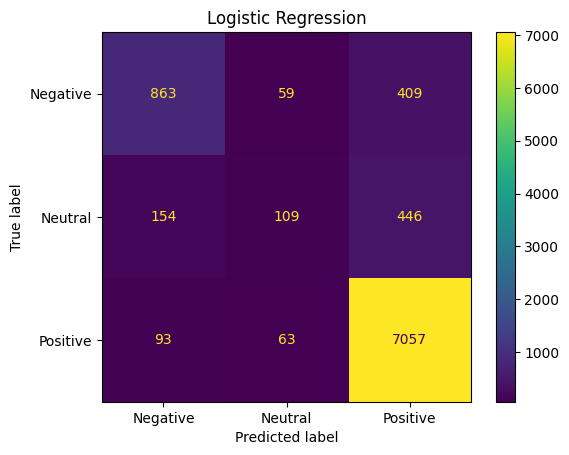

In [6]:
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(max_iter=1000)

log_reg.fit(train_tfidf, train_labels)

log_reg_predictions = log_reg.predict(test_tfidf)

evaluate("Logistic Regression", test_labels, log_reg_predictions)

Top 10 Words for Positive and Negative

In [9]:
tfidf_vocabulary = tfidf.get_feature_names_out()

# Each row of log_reg.coef_ holds one weight per word for one class.
# The largest weights are the words that push hardest toward that class.
top_words = {}
for sentiment in ["Positive", "Negative"]:
    class_index = list(log_reg.classes_).index(sentiment)
    weights = pd.Series(log_reg.coef_[class_index], index=tfidf_vocabulary)
    top = weights.nlargest(10)
    top_words[f"{sentiment} word"] = top.index
    top_words[f"{sentiment} weight"] = top.values.round(2)

# Show both lists side by side, ranked 1-10
top_words_table = pd.DataFrame(top_words, index=range(1, 11))
top_words_table

,Positive word,Positive weight,Negative word,Negative weight
1,great,7.81,not,4.34
2,best,6.59,worst,4.22
3,delicious,6.29,awful,3.95
4,excellent,5.51,disappointing,3.53
5,love,5.40,terrible,3.50
6,perfect,4.71,disappointed,3.43
7,wonderful,4.25,yuck,3.35
8,good,3.94,threw,3.22
9,yummy,3.71,nasty,3.07
10,loves,3.71,horrible,3.03


Error Analysis

In [12]:
wrong = test_labels != log_reg_predictions

errors = test_df[wrong].copy()
errors["Predicted"] = log_reg_predictions[wrong]

print("Misclassified reviews:", len(errors), "of", len(test_df))
print()

# Pick 10 misclassified reviews (same 10 every run) and print each one in full
error_sample = errors.sample(10, random_state=48)

for number, (_, review) in enumerate(error_sample.iterrows(), start=1):
    print(f"Review {number} | Actual: {review['Sentiment']} | Predicted: {review['Predicted']}")
    print(review["CombinedText"])
    print()

Misclassified reviews: 1224 of 9253

Review 1 | Actual: Neutral | Predicted: Positive
Love the bar, but a bit expensive KIND bars are so delicious, and good for you. I just really wish they were not so expensive. This Almond and Coconut flavor happens to be my favorite!

Review 2 | Actual: Neutral | Predicted: Negative
Dog was not excited Treats smelled good but dog didn't seem really interested. She is a lab and very treat motivated so not sure why she didn't like these. She loves dried sweet potatoes. Seller shipped really fast and product was not old. Have to do 3 stars because the dog didn't like them.

Review 3 | Actual: Negative | Predicted: Neutral
Reading this description you would think... This was the healthiest thing since, well, fruit. One can contains a whopping 33 sugar grams and 35 carbs. While it may be "natural", be careful how much you drink! As far as taste, it was just OK. It tasted like bubbly apple juice, even though it said "black cherry" right on the can the tas